# 2. Image Sensors

Practice for module 2: photon shot noise (Poisson), a simple sensor noise model and the SNR it gives at
different light levels, quantization noise, estimating λ from the zero count, dynamic range in dB, gamma,
and multi-exposure HDR (and what happens when the scene moves).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(0)

## 2.1 Photon shot noise

Photon arrivals are Poisson, so the variance equals the mean and the SNR grows as `√N`. Since
`P(k = 0) = e^(−λ)`, the mean can be estimated from how often a pixel sees zero photons.

In [2]:
for lam in [1, 10, 100, 10000]:
    k = rng.poisson(lam, 200_000)
    print(f"λ = {lam:5d}: mean {k.mean():9.2f}, variance {k.var():9.2f}, SNR {k.mean() / k.std():6.1f} (√λ = {np.sqrt(lam):.1f})")
k = rng.poisson(0.7, 100_000)
print(f"\nP(0) = {(k == 0).mean():.4f} -> λ = -ln P(0) = {-np.log((k == 0).mean()):.3f} (true 0.7)")

λ =     1: mean      1.00, variance      1.00, SNR    1.0 (√λ = 1.0)
λ =    10: mean     10.01, variance     10.02, SNR    3.2 (√λ = 3.2)
λ =   100: mean    100.03, variance    100.18, SNR   10.0 (√λ = 10.0)
λ = 10000: mean  10000.16, variance  10002.09, SNR  100.0 (√λ = 100.0)

P(0) = 0.4982 -> λ = -ln P(0) = 0.697 (true 0.7)


## 2.2 A sensor noise model

photons → electrons with quantum efficiency < 1 (binomial thinning), plus dark current (Poisson, scene
independent), readout noise (Gaussian, scene independent), full-well clipping and a 10-bit ADC. At low
light the readout and dark noise dominate; at high light the shot noise does, until the pixel saturates.

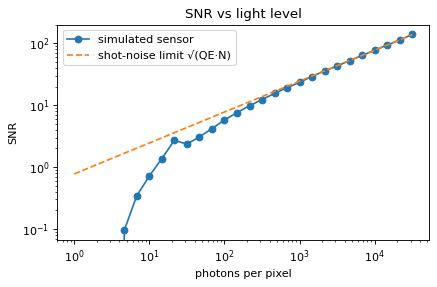

In [3]:
def sensor(photons, qe=0.6, dark=5, read=3, full_well=20000, bits=10):
    e = rng.binomial(rng.poisson(photons), qe) + rng.poisson(dark, photons.shape)
    e = np.minimum(e + rng.normal(0, read, photons.shape), full_well)
    step = full_well / 2 ** bits
    return np.round(e / step) * step

levels = np.logspace(0, 4.5, 28)
snr = []
for L in levels:
    out = sensor(np.full(20000, L))
    snr.append((out.mean() - 5) / out.std())        # signal = mean minus dark level
plt.figure(figsize=(6, 3.5))
plt.loglog(levels, snr, "o-", label="simulated sensor")
plt.loglog(levels, np.sqrt(0.6 * levels), "--", label="shot-noise limit √(QE·N)")
plt.xlabel("photons per pixel"); plt.ylabel("SNR"); plt.legend(); plt.title("SNR vs light level")
plt.show()

Below ~100 photons the curve falls under the shot-noise line because readout and dark noise do not depend
on the scene. Above that the sensor is shot-noise limited, and the best SNR is set by the full-well capacity.

## 2.3 Quantization noise and dynamic range

Uniform quantization with step `Δ` adds noise of variance `Δ²/12`; each extra bit halves `Δ`.
Dynamic range in dB is `20 log10(max / min)`.

In [4]:
x = rng.uniform(0, 1, 500_000)
for bits in [4, 6, 8, 10]:
    d = 1 / 2 ** bits
    q = np.floor(x / d) * d + d / 2
    print(f"{bits:2d} bits: Δ = {d:.5f}, noise variance {np.var(q - x):.3e}, Δ²/12 = {d * d / 12:.3e}")
print(f"\nsensor above: full well 20000 e-, read noise 3 e- -> {20 * np.log10(20000 / 3):.1f} dB")
print(f"10-bit ADC alone: {20 * np.log10(2 ** 10):.1f} dB")

 4 bits: Δ = 0.06250, noise variance 3.249e-04, Δ²/12 = 3.255e-04
 6 bits: Δ = 0.01562, noise variance 2.034e-05, Δ²/12 = 2.035e-05
 8 bits: Δ = 0.00391, noise variance 1.270e-06, Δ²/12 = 1.272e-06
10 bits: Δ = 0.00098, noise variance 7.928e-08, Δ²/12 = 7.947e-08

sensor above: full well 20000 e-, read noise 3 e- -> 76.5 dB
10-bit ADC alone: 60.2 dB


## 2.4 Gamma and multi-exposure HDR

A scene with radiance spanning 4 orders of magnitude. One 8-bit exposure either clips the highlights or
crushes the shadows. Merging several exposures (weighting pixels that are neither dark nor saturated, and
dividing by exposure time) recovers the full linear range. If something moves between exposures, the
merge produces ghosts.

relative error of merged radiance: median 0.005


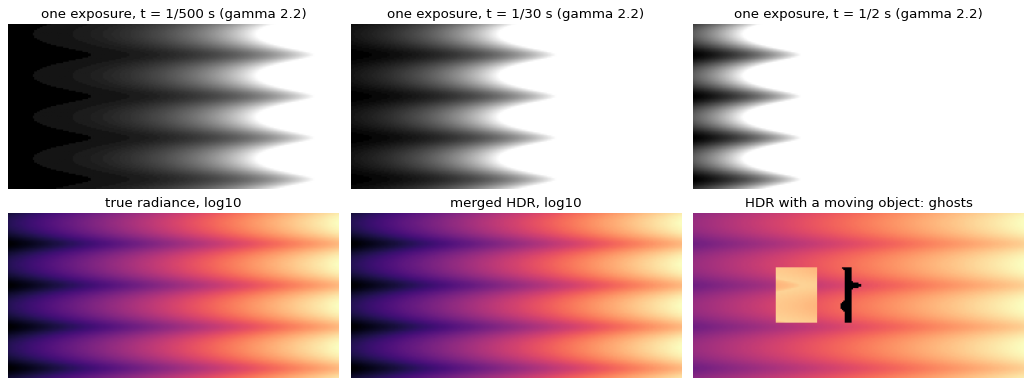

In [5]:
y, x = np.mgrid[:120, :240] / np.array([120, 240])[:, None, None]
radiance = 10 ** (4 * x) * (0.6 + 0.4 * np.sin(8 * np.pi * y))       # 1 .. 10^4
times = [1 / 8000, 1 / 500, 1 / 30, 1 / 2]

def expose(rad, t):
    return np.clip(np.round(255 * rad * t / 2), 0, 255)

def merge(shots):
    num = np.zeros_like(radiance); den = np.zeros_like(radiance)
    for z, t in zip(shots, times):
        w = np.where((z > 5) & (z < 250), 1 - np.abs(z / 127.5 - 1), 0)
        num += w * z * 2 / 255 / t; den += w
    return num / np.maximum(den, 1e-9)

shots = [expose(radiance, t) for t in times]
hdr = merge(shots)
ok = (radiance > 2)
print(f"relative error of merged radiance: median {np.median(np.abs(hdr[ok] / radiance[ok] - 1)):.3f}")

moving = []
for k, t in enumerate(times):
    r = radiance.copy(); r[40:80, 60 + 25 * k:90 + 25 * k] = 3000      # an object moving between shots
    moving.append(expose(r, t))

fig, axes = plt.subplots(2, 3, figsize=(13, 5))
for a, z, t in zip(axes[0], shots[1:], times[1:]):
    a.imshow(255 * (z / 255) ** (1 / 2.2), cmap="gray"); a.set_title(f"one exposure, t = 1/{1 / t:.0f} s (gamma 2.2)")
axes[1, 0].imshow(np.log10(radiance), cmap="magma"); axes[1, 0].set_title("true radiance, log10")
axes[1, 1].imshow(np.log10(hdr + 1e-3), cmap="magma"); axes[1, 1].set_title("merged HDR, log10")
axes[1, 2].imshow(np.log10(merge(moving) + 1e-3), cmap="magma"); axes[1, 2].set_title("HDR with a moving object: ghosts")
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()